Power spectra for particle decaying for the FOSSIL science paper

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 
import tol_colors as tc

import tools
import my_plot as mplt

from plot_utils import set_size, set_colors, width_jcap, sci_formatter
plt.style.use('my_style.mplstyle')

In [2]:

colors = set_colors(4, palette="sns:colorblind")
colors2 = tc.colorsets['vibrant']

In [3]:
def extract_PS(folder_path, ellmax, ymax, gammax):
    """Extract power spectra from the output of the FH code. """
    folder = Path(folder_path) / "batch" / "FH" / "yn_T_aniso_system" 
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_nmax_{zcon}.dat"))
    file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_Gamma_X_{gammax}.dat"))
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}.dat"))

    ell = []
    TT = []
    muT = []
    yT = []
    deltaTT = []
    EE = []

    ell = np.loadtxt(file_path, comments='#')[:, 0]
    TT = np.loadtxt(file_path, comments='#')[:, 1]
    deltaTT = np.loadtxt(file_path, comments='#')[:, 3]
    muT = np.loadtxt(file_path, comments='#')[:, 4]
    yT = np.loadtxt(file_path, comments='#')[:, 5]
    EE = np.loadtxt(file_path, comments='#')[:, 6]

    return np.array(ell), np.array(TT), np.array(EE), np.array(yT), np.array(muT), np.array(deltaTT)

In [4]:
ell, TT, EE, yT_1, muT_1, deltaTT_1 = extract_PS("../Data/fossil_plot/outputs_dp_PS-decparticles/",15,15,"001")
_ , _ , _ , yT_2, muT_2, deltaTT_2 = extract_PS("../Data/fossil_plot/outputs_dp_PS-decparticles/",15,15,"002")
_ , _ , _ , yT_3, muT_3, deltaTT_3 = extract_PS("../Data/fossil_plot/outputs_dp_PS-decparticles/",15,15,"003")

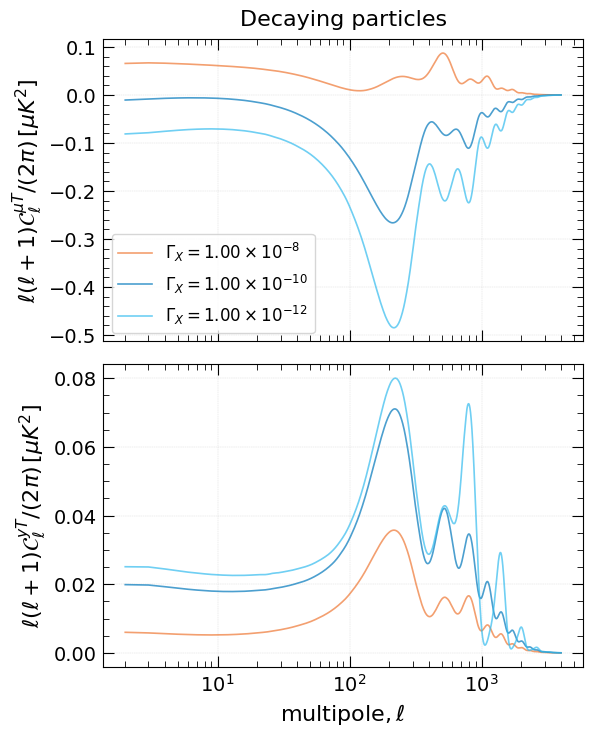

In [5]:
fig, ax = plt.subplots(2, 1, figsize=set_size(width_jcap, 1, (2,1)), sharex='col')


ax[0].plot(ell, muT_1, color=colors2[0], alpha=0.7, linestyle="-",  label=f"$\\Gamma_{{X}} = ${tools.sci_notation(1e-8)}")
ax[0].plot(ell, muT_2, color=colors2[1], alpha=0.7, linestyle="-",  label=f"$\\Gamma_{{X}} = ${tools.sci_notation(1e-10)}")
ax[0].plot(ell, muT_3, color=colors2[2], alpha=0.7, linestyle="-",  label=f"$\\Gamma_{{X}} = ${tools.sci_notation(1e-12)}")


ax[1].plot(ell, yT_1, color=colors2[0], alpha=0.7, linestyle="-")
ax[1].plot(ell, yT_2, color=colors2[1], alpha=0.7, linestyle="-")
ax[1].plot(ell, yT_3, color=colors2[2], alpha=0.7, linestyle="-")


for a in ax:
    a.set_xscale('log')
    # a.set_yscale('log')

ax[0].tick_params(labelbottom=False)

ax[0].set_ylabel("$\\ell(\\ell + 1) \\mathcal{C}_\\ell^{{\\mu T}} / (2 \\pi) \\, [\\mu K^2]$")
ax[1].set_ylabel("$\\ell(\\ell + 1) \\mathcal{C}_\\ell^{{y T}} / (2 \\pi) \\, [\\mu K^2]$")
ax[1].set_xlabel("$\\mathrm{multipole}, \\ell$")

ax[0].legend()
ax[0].set_title("Decaying particles")


plt.savefig('outputs/PS-decparticles.pdf', dpi=300, bbox_inches="tight")
plt.show()